# Práctica 3 — Visión por Computador

Este notebook reúne las **dos tareas**: detección y suma de monedas, y clasificación de microplásticos (FRA / PEL / TAR).

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [3]:
# Definición de monedas Euro: (nombre, diámetro_mm, valor_euros, tipo_color)
# tipo_color: "bimetalica", "dorada", "cobriza"
# Guardamos los datos reales de las monedas para compararlos con las medidas de la imagen.
MONEDAS_EURO = [
    ("2 euro",      25.75, 2.00, "bimetalica"),
    ("50 centimos", 24.25, 0.50, "dorada"),
    ("1 euro",      23.25, 1.00, "bimetalica"),
    ("20 centimos", 22.25, 0.20, "dorada"),
    ("5 centimos",  21.25, 0.05, "cobriza"),
    ("10 centimos", 19.75, 0.10, "dorada"),
    ("2 centimos",  18.75, 0.02, "cobriza"),
    ("1 centimo",   16.25, 0.01, "cobriza"),
]

# Colores para visualización según tipo
COLORES_TIPO = {
    "bimetalica": (0, 255, 255),   # Amarillo (BGR)
    "dorada":     (0, 200, 255),    # Naranja (BGR)
    "cobriza":    (0, 100, 200),    # Marrón/cobre (BGR)
    "desconocida": (255, 255, 255), # Blanco
}


In [4]:
def clasificar_color_moneda(img_bgr, cx, cy, radio):
    """
    Clasifica el color de una moneda analizando la región central
    en el espacio HSV.
    
    Las monedas bimetálicas (1€, 2€) tienen una diferencia notable
    de saturación/hue entre su centro y su borde exterior.
    Las cobrizas tienen hue bajo (rojizo) y alta saturación.
    Las doradas tienen hue medio y saturación moderada-alta.
    
    Retorna: "bimetalica", "dorada" o "cobriza"
    """
    # HSV nos viene bien para separar el tono del color de la cantidad de brillo.
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    h, w = img_bgr.shape[:2]
    
    # Máscara circular en la zona central (50% del radio)
    # Miramos primero el centro de la moneda.
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask, (int(cx), int(cy)), max(1, int(radio * 0.5)), 255, -1)
    mean_hsv = cv2.mean(hsv, mask=mask)[:3]
    hue, sat, val = mean_hsv
    
    # Zona anular exterior (entre 60% y 90% del radio)
    # También miramos un anillo exterior: así podemos reconocer las bimetálicas.
    mask_outer = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask_outer, (int(cx), int(cy)), max(1, int(radio * 0.9)), 255, -1)
    mask_inner = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask_inner, (int(cx), int(cy)), max(1, int(radio * 0.6)), 255, -1)
    mask_ring = cv2.subtract(mask_outer, mask_inner)
    mean_hsv_outer = cv2.mean(hsv, mask=mask_ring)[:3]
    
    # Diferencia entre centro y borde
    # Si el centro y el borde tienen colores diferentes, probablemente es de 1 o 2 euros.
    sat_diff = abs(mean_hsv[1] - mean_hsv_outer[1])
    hue_diff = abs(mean_hsv[0] - mean_hsv_outer[0])
    
    # Bimetálica: gran diferencia de saturación o hue entre centro y borde
    if sat_diff > 25 or hue_diff > 8:
        return "bimetalica"
    
    # Cobriza: hue bajo (rojizo) y alta saturación
    if hue < 12 and sat > 100:
        return "cobriza"
    
    # Dorada: hue entre 12-30 y saturación moderada-alta
    if 12 <= hue <= 30 and sat > 80:
        return "dorada"
    
    # Si baja saturación, probablemente bimetálica (parte plateada)
    if sat < 40:
        return "bimetalica"
    
    return "dorada"


In [5]:
def clasificar_moneda(diametro_mm, tipo_color):
    """
    Clasifica una moneda a partir de su diámetro en mm y su tipo de color.
    Busca la moneda más cercana en diámetro que sea compatible con el color.
    Se penaliza la distancia si el tipo de color no coincide.
    
    Retorna: (nombre, valor_euros)
    """
    mejor_match = None
    mejor_dist = float("inf")
    
    for nombre, diam, valor, color in MONEDAS_EURO:
        dist = abs(diametro_mm - diam)
        
        # Priorizar monedas del mismo tipo de color
        if color == tipo_color:
            dist_efectiva = dist
        else:
            # Penalización por no coincidir el color
            dist_efectiva = dist + 5.0
        
        if dist_efectiva < mejor_dist:
            mejor_dist = dist_efectiva
            mejor_match = (nombre, valor)
    
    return mejor_match


In [6]:
def detectar_monedas_contornos(img_bgr, px_por_mm, umbral=None, area_min=5000):
    """
    Detecta monedas usando umbralizado + contornos.
    El diámetro se estima a partir del área del contorno (diámetro equivalente).
    
    Args:
        img_bgr: Imagen en BGR
        px_por_mm: Relación píxeles por milímetro
        umbral: Umbral fijo (None = Otsu automático)
        area_min: Área mínima de contorno para considerar como moneda
    
    Retorna: (img_resultado, lista_monedas, total_euros)
    """
    img_result = img_bgr.copy()
    # Pasamos a gris para separar mejor objetos y fondo.
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    # Umbralizado
    # Si no damos un umbral, Otsu elige uno de forma automática.
    if umbral is None:
        _, thresh = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    else:
        _, thresh = cv2.threshold(gris, umbral, 255, cv2.THRESH_BINARY_INV)
    
    # Buscar contornos externos
    # Buscamos el borde exterior de las zonas blancas de la máscara.
    contornos, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    monedas_detectadas = []
    total = 0.0
    
    for c in contornos:
        # Eliminamos manchas pequeñas para no contarlas como monedas.
        area = cv2.contourArea(c)
        if area < area_min:
            continue
        
        # Centro y radio del círculo envolvente mínimo
        # Aproximamos el objeto con un círculo para sacar su centro y tamaño.
        (cx, cy), radio_enclosing = cv2.minEnclosingCircle(c)
        
        # Diámetro equivalente a partir del área (más preciso para formas circulares)
        equiv_diam_px = np.sqrt(4 * area / np.pi)
        radio_px = equiv_diam_px / 2
        
        # Verificar circularidad: relación área / área del círculo envolvente
        # Comprobamos que se parezca lo suficiente a un círculo.
        circularidad = area / (np.pi * radio_enclosing**2)
        if circularidad < 0.5:  # No es suficientemente circular
            continue
        
        # Convertir a mm
        # Pasamos el tamaño en píxeles a milímetros con la calibración.
        diametro_mm = equiv_diam_px / px_por_mm
        
        # Clasificar color
        # Con tamaño y color decidimos qué moneda es y la sumamos.
        tipo_color = clasificar_color_moneda(img_bgr, cx, cy, radio_px)
        
        # Clasificar moneda
        nombre, valor = clasificar_moneda(diametro_mm, tipo_color)
        total += valor
        
        # Guardamos los datos de cada moneda por si queremos revisarlos.
        monedas_detectadas.append({
            "nombre": nombre,
            "valor": valor,
            "centro": (int(cx), int(cy)),
            "radio_px": int(radio_px),
            "diametro_mm": diametro_mm,
            "tipo_color": tipo_color,
            "circularidad": circularidad,
        })
        
        # Dibujar
        color_dibujo = COLORES_TIPO.get(tipo_color, (255, 255, 255))
        cv2.circle(img_result, (int(cx), int(cy)), int(radio_px), color_dibujo, 2)
        cv2.circle(img_result, (int(cx), int(cy)), 3, color_dibujo, -1)
        
        texto = f"{nombre} ({valor:.2f}E)"
        cv2.putText(img_result, texto,
                   (int(cx) - int(radio_px), int(cy) - int(radio_px) - 10),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.45, color_dibujo, 1)
        texto_mm = f"{diametro_mm:.1f}mm"
        cv2.putText(img_result, texto_mm,
                   (int(cx) - 20, int(cy) + 5),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)
    
    # Total
    # Mostramos el importe acumulado sobre la imagen.
    texto_total = f"Total: {total:.2f} EUR ({len(monedas_detectadas)} monedas)"
    cv2.putText(img_result, texto_total, (10, 30),
               cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    
    return img_result, monedas_detectadas, total


In [7]:
def detectar_monedas_hough(img_bgr, px_por_mm,
                           min_radius_px=15, max_radius_px=200,
                           param1=100, param2=50, min_dist=50,
                           blur_ksize=7):
    """
    Detecta monedas usando la Transformada de Hough para círculos.
    Más adecuada para detección en tiempo real (webcam).
    
    Retorna: (img_resultado, lista_monedas, total_euros)
    """
    img_result = img_bgr.copy()
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    # En vídeo suavizamos el ruido antes de buscar círculos.
    gris_blur = cv2.medianBlur(gris, blur_ksize)
    
    # Hough busca directamente círculos; no necesitamos extraer contornos como antes.
    circulos = cv2.HoughCircles(
        gris_blur,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=min_dist,
        param1=param1,
        param2=param2,
        minRadius=min_radius_px,
        maxRadius=max_radius_px,
    )
    
    monedas_detectadas = []
    total = 0.0
    
    # Solo clasificamos si realmente se han encontrado círculos.
    if circulos is not None:
        circulos = np.uint16(np.around(circulos))
        for circ in circulos[0, :]:
            cx, cy, radio_px = circ
            # Para cada círculo usamos su radio y la escala actual.
            diametro_mm = (2 * radio_px) / px_por_mm
            tipo_color = clasificar_color_moneda(img_bgr, cx, cy, radio_px)
            nombre, valor = clasificar_moneda(diametro_mm, tipo_color)
            total += valor
            
            monedas_detectadas.append({
                "nombre": nombre,
                "valor": valor,
                "centro": (int(cx), int(cy)),
                "radio_px": int(radio_px),
                "diametro_mm": diametro_mm,
                "tipo_color": tipo_color,
            })
            
            color_dibujo = COLORES_TIPO.get(tipo_color, (255, 255, 255))
            cv2.circle(img_result, (int(cx), int(cy)), int(radio_px), color_dibujo, 2)
            cv2.circle(img_result, (int(cx), int(cy)), 3, color_dibujo, -1)
            texto = f"{nombre} ({valor:.2f}E)"
            cv2.putText(img_result, texto,
                       (int(cx) - int(radio_px), int(cy) - int(radio_px) - 10),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.45, color_dibujo, 1)
            texto_mm = f"{diametro_mm:.1f}mm"
            cv2.putText(img_result, texto_mm,
                       (int(cx) - 20, int(cy) + 5),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)
    
    texto_total = f"Total: {total:.2f} EUR ({len(monedas_detectadas)} monedas)"
    cv2.putText(img_result, texto_total, (10, 30),
               cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    
    return img_result, monedas_detectadas, total


---
## Paso 1: Detección en la imagen estática (`Monedas.jpg`)

Cargamos la imagen, aplicamos umbralizado Otsu y detectamos contornos.
Usamos la moneda más grande (2€) como referencia para calibrar la relación píxeles/mm.
El diámetro de cada moneda se estima usando el diámetro equivalente a partir del área del contorno,
que es más preciso que el radio del círculo de Hough.


Imagen cargada: (938, 473, 3)


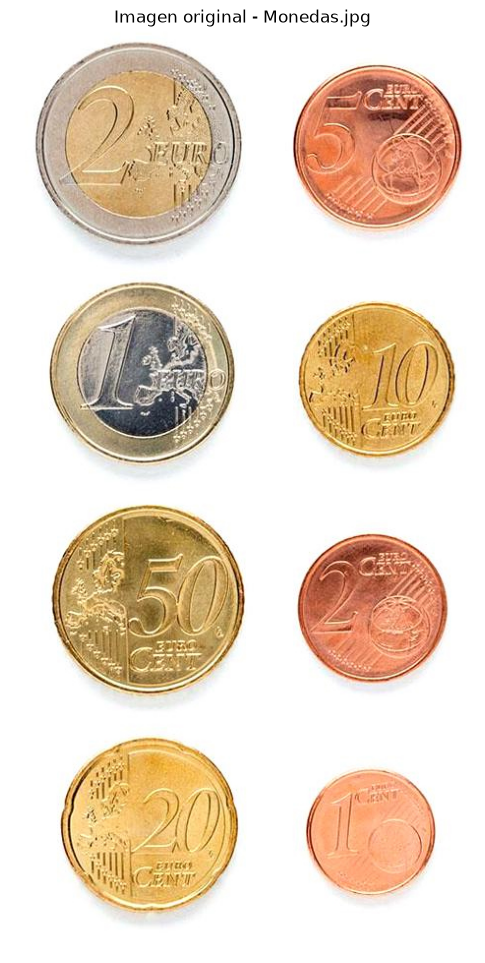

In [8]:
# Cargar imagen
# Leemos la foto y comprobamos que está disponible.
img = cv2.imread("Monedas.jpg")
if img is None:
    raise FileNotFoundError("No se encontró Monedas.jpg")
print(f"Imagen cargada: {img.shape}")

# Mostrar la imagen original
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(6, 12))
plt.imshow(img_rgb)
plt.title("Imagen original - Monedas.jpg")
plt.axis("off")
plt.show()


Umbral Otsu seleccionado: 204.0
Contornos encontrados: 50
Contornos de monedas (área > 5000): 8


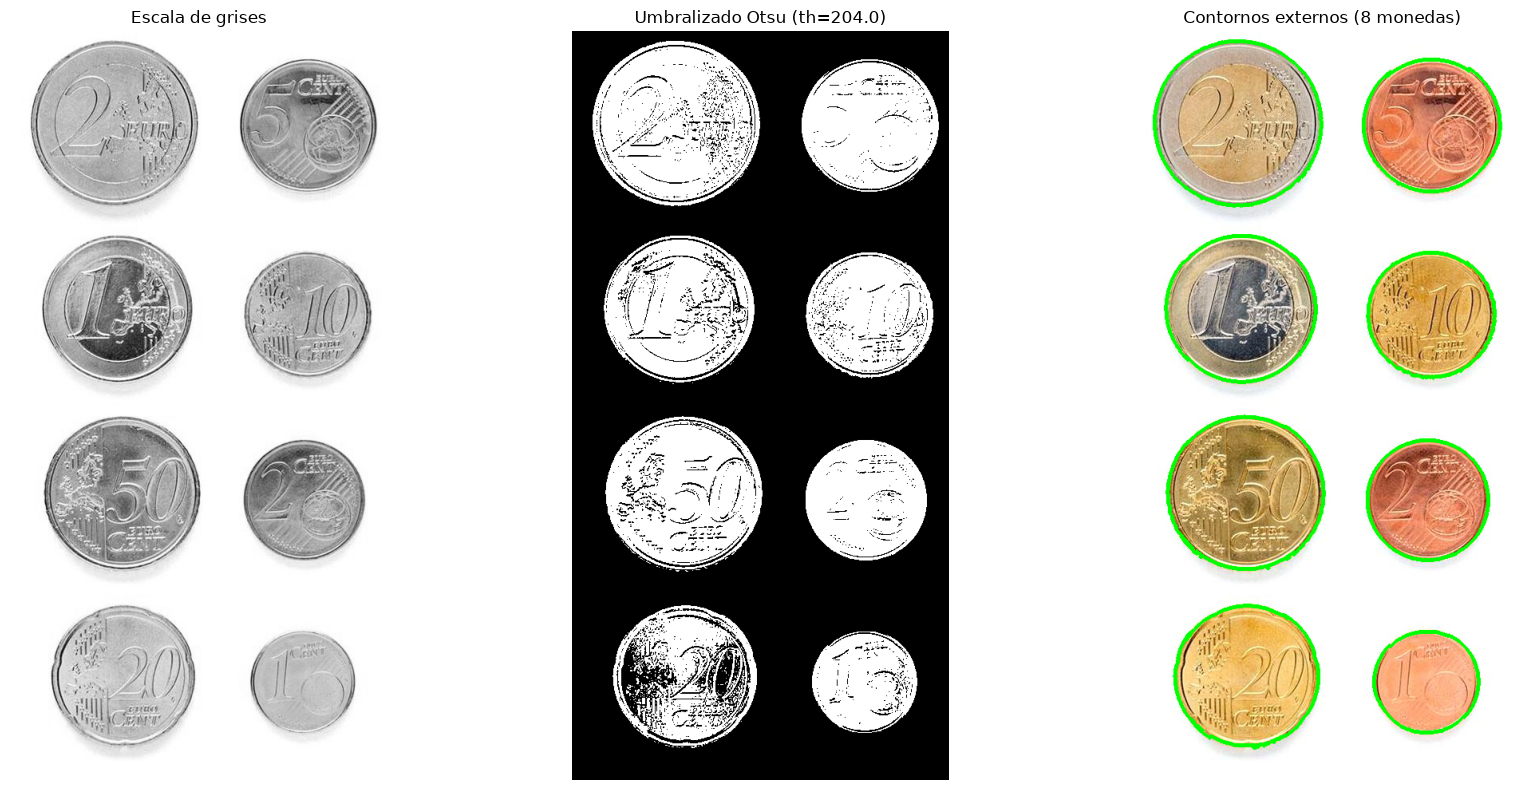

In [9]:
# Convertir a escala de grises
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Umbralizado Otsu
# Otsu deja las monedas y el fondo separados en blanco y negro.
otsu_th, thresh = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print(f"Umbral Otsu seleccionado: {otsu_th}")

# Buscar contornos externos
contornos, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print(f"Contornos encontrados: {len(contornos)}")

# Filtrar por área mínima (eliminar ruido)
# Filtramos por área para quedarnos con los objetos grandes.
contornos_monedas = [c for c in contornos if cv2.contourArea(c) > 5000]
print(f"Contornos de monedas (área > 5000): {len(contornos_monedas)}")

# Visualizar umbralizado y contornos
# Enseñamos cada fase para ver dónde falla si detecta mal.
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

axes[0].imshow(gris, cmap="gray")
axes[0].set_title("Escala de grises")
axes[0].axis("off")

axes[1].imshow(thresh, cmap="gray")
axes[1].set_title(f"Umbralizado Otsu (th={otsu_th})")
axes[1].axis("off")

img_contornos = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()
cv2.drawContours(img_contornos, contornos_monedas, -1, (0, 255, 0), 3)
axes[2].imshow(img_contornos)
axes[2].set_title(f"Contornos externos ({len(contornos_monedas)} monedas)")
axes[2].axis("off")

plt.tight_layout()
plt.show()


In [10]:
# Calibración: encontrar la moneda más grande (2 euro)
# Calcular diámetro equivalente de cada contorno
# Calculamos el diámetro de cada contorno a partir del área.
diametros_px = []
for c in contornos_monedas:
    area = cv2.contourArea(c)
    equiv_diam = np.sqrt(4 * area / np.pi)
    diametros_px.append(equiv_diam)

# La moneda más grande es la de 2 euro (25.75 mm de diámetro)
# Suponemos que la moneda mayor es de 2 euros: esto es una limitación.
max_diam_px = max(diametros_px)
DIAMETRO_REF_MM = 25.75  # 2 euro
# Esta escala sirve para convertir todas las demás medidas a mm.
px_por_mm = max_diam_px / DIAMETRO_REF_MM

print(f"Calibración:")
print(f"  Moneda de referencia: 2 euro (diámetro = {DIAMETRO_REF_MM} mm)")
print(f"  Diámetro equivalente en píxeles: {max_diam_px:.1f} px")
print(f"  Relación: {px_por_mm:.2f} px/mm")
print()

# Mostrar todos los diámetros encontrados
print("Diámetros equivalentes detectados (mm):")
for d in sorted(diametros_px, reverse=True):
    print(f"  {d/px_por_mm:.1f} mm ({d:.1f} px)")


Calibración:
  Moneda de referencia: 2 euro (diámetro = 25.75 mm)
  Diámetro equivalente en píxeles: 207.2 px
  Relación: 8.05 px/mm

Diámetros equivalentes detectados (mm):
  25.8 mm (207.2 px)
  24.0 mm (192.9 px)
  23.0 mm (184.8 px)
  22.1 mm (177.5 px)
  20.9 mm (167.9 px)
  19.5 mm (157.3 px)
  18.8 mm (150.9 px)
  16.0 mm (128.7 px)


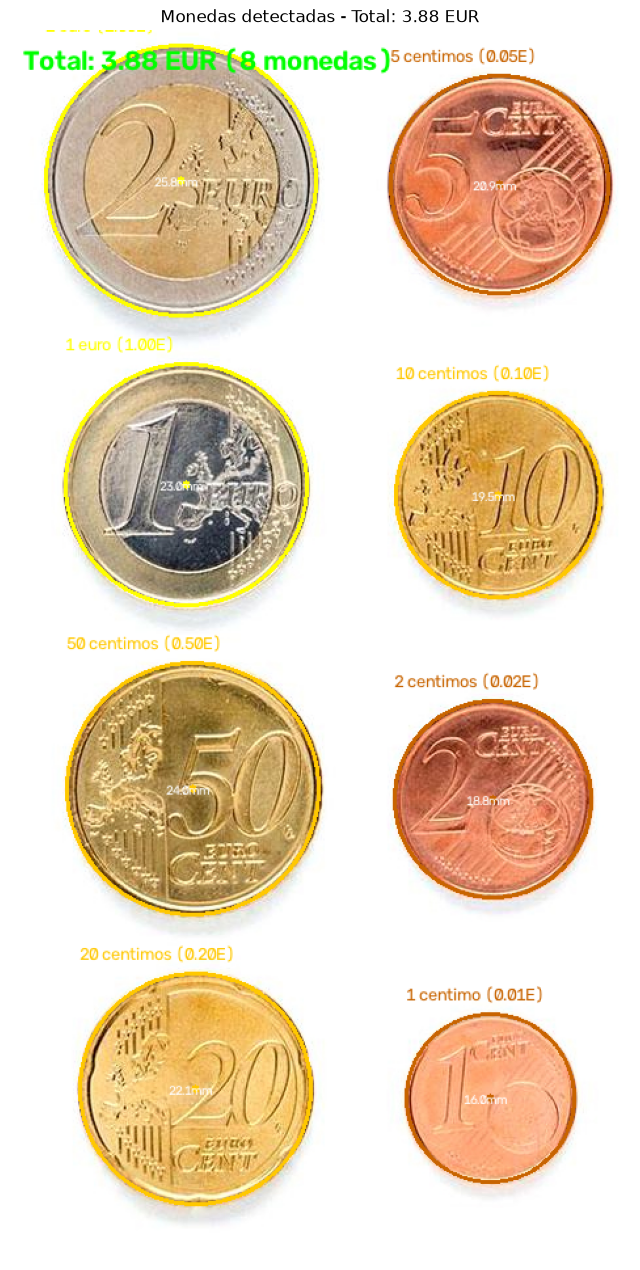


RESUMEN DE MONEDAS DETECTADAS
  1.       1 centimo |  0.01 EUR | diam  16.0 mm | color:     cobriza | circ: 0.96
  2.     20 centimos |  0.20 EUR | diam  22.1 mm | color:      dorada | circ: 0.96
  3.      2 centimos |  0.02 EUR | diam  18.8 mm | color:     cobriza | circ: 0.98
  4.     50 centimos |  0.50 EUR | diam  24.0 mm | color:      dorada | circ: 0.96
  5.     10 centimos |  0.10 EUR | diam  19.5 mm | color:      dorada | circ: 0.97
  6.          1 euro |  1.00 EUR | diam  23.0 mm | color:  bimetalica | circ: 0.96
  7.      5 centimos |  0.05 EUR | diam  20.9 mm | color:     cobriza | circ: 0.96
  8.          2 euro |  2.00 EUR | diam  25.8 mm | color:  bimetalica | circ: 0.97
-----------------------------------------------------------------
  TOTAL: 3.88 EUR  (8 monedas)
  ESPERADO: 3.88 EUR (8 monedas)


In [11]:
# Detección y clasificación de todas las monedas
# Reutilizamos la función principal: detecta, clasifica, dibuja y suma.
img_resultado, monedas, total = detectar_monedas_contornos(
    img, px_por_mm, area_min=5000
)

# Mostrar resultados
plt.figure(figsize=(8, 16))
plt.imshow(cv2.cvtColor(img_resultado, cv2.COLOR_BGR2RGB))
plt.title(f"Monedas detectadas - Total: {total:.2f} EUR")
plt.axis("off")
plt.show()

# Resumen detallado
print("\n" + "="*65)
print("RESUMEN DE MONEDAS DETECTADAS")
print("="*65)
for i, m in enumerate(monedas):
    print(f'  {i+1}. {m["nombre"]:>15s} | {m["valor"]:>5.2f} EUR | '
          f'diam {m["diametro_mm"]:>5.1f} mm | color: {m["tipo_color"]:>11s} | '
          f'circ: {m["circularidad"]:.2f}')
print("-"*65)
print(f"  TOTAL: {total:.2f} EUR  ({len(monedas)} monedas)")
print(f"  ESPERADO: 3.88 EUR (8 monedas)")
print("="*65)


## Paso 2: Demostrador en vivo (Webcam)

El siguiente código captura vídeo de la webcam y detecta monedas en tiempo real
usando la Transformada de Hough para círculos.

### Instrucciones:
1. Ejecuta la celda siguiente.
2. Se abrirá una ventana con la imagen de la webcam.
3. **Calibra**: pulsa `c` y haz clic en una moneda de 1€, o pulsa `a` para auto-calibración (la moneda más grande = 2€).
4. La detección y clasificación se realizan continuamente.
5. Pulsa `q` o `ESC` para salir.

### Controles:
| Tecla | Acción |
|-------|--------|
| `c` | Modo calibración (clic en moneda de 1€) |
| `a` | Auto-calibración (moneda más grande = 2€) |
| `+`/`-` | Ajustar sensibilidad del detector |
| `q`/`ESC` | Salir |


In [19]:
def demo_webcam():
    """Demostrador en vivo de detección y conteo de monedas con webcam."""
    # Abrimos la cámara; si no aparece imagen puede haber que cambiar el índice.
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("Error: No se pudo abrir la webcam.")
        return
    
    # Al principio no conocemos la escala; hay que calibrarla.
    px_por_mm_live = None
    modo_calibracion = False
    clicked_point_live = None
    param2_hough = 50


    # El clic sobre una moneda de 1 euro permite calibrar manualmente.
    def on_mouse(event, x, y, flags, param):
        nonlocal clicked_point_live
        if event == cv2.EVENT_LBUTTONDOWN and modo_calibracion:
            clicked_point_live = (x, y)
    
    cv2.namedWindow("Detector de Monedas", cv2.WINDOW_NORMAL)
    cv2.setMouseCallback("Detector de Monedas", on_mouse)
    
    print("Controles:")
    print("  c - Modo calibración (clic en moneda de 1 euro)")
    print("  a - Calibración automática (moneda más grande = 2 euro)")
    print("  +/- - Ajustar sensibilidad")
    print("  q/ESC - Salir")
    
    # Procesamos los fotogramas de la webcam uno detrás de otro.
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        
        display_frame = frame.copy()
        gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gris_blur = cv2.medianBlur(gris, 7)
        
        # Parámetros adaptativos según resolución
        h_frame, w_frame = frame.shape[:2]
        min_r = max(15, int(min(h_frame, w_frame) * 0.03))
        max_r = int(min(h_frame, w_frame) * 0.25)
        min_d = max(30, int(min(h_frame, w_frame) * 0.08))
        
        # Detectar círculos con Hough
        # Localizamos círculos en el fotograma actual.
        circulos_live = cv2.HoughCircles(
            gris_blur,
            cv2.HOUGH_GRADIENT,
            dp=1,
            minDist=min_d,
            param1=100,
            param2=param2_hough,
            minRadius=min_r,
            maxRadius=max_r,
        )
        
        # Modo calibración
        if modo_calibracion:
            cv2.putText(display_frame, "CALIBRACION: Clic en moneda de 1 euro",
                       (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
            
            if clicked_point_live is not None and circulos_live is not None:
                best_dist = float("inf")
                best_radio = None
                for c in circulos_live[0]:
                    d = np.sqrt((c[0]-clicked_point_live[0])**2 + 
                               (c[1]-clicked_point_live[1])**2)
                    if d < best_dist:
                        best_dist = d
                        best_radio = c[2]
                if best_radio is not None:
                    px_por_mm_live = (2 * best_radio) / 23.25  # 1 euro
                    print(f"Calibrado con 1 euro: {px_por_mm_live:.2f} px/mm")
                modo_calibracion = False
                clicked_point_live = None
        
        # Si está calibrado, clasificar monedas
        if px_por_mm_live is not None and circulos_live is not None:
            total_live = 0.0
            n_monedas = 0
            for circ in circulos_live[0]:
                cx, cy, radio_px = circ
                diametro_mm = (2 * radio_px) / px_por_mm_live
                tipo_color = clasificar_color_moneda(frame, cx, cy, radio_px)
                nombre, valor = clasificar_moneda(diametro_mm, tipo_color)
                total_live += valor
                n_monedas += 1
                
                color_d = COLORES_TIPO.get(tipo_color, (255, 255, 255))
                cv2.circle(display_frame, (int(cx), int(cy)), int(radio_px), color_d, 2)
                cv2.circle(display_frame, (int(cx), int(cy)), 3, color_d, -1)
                cv2.putText(display_frame, f"{nombre} ({valor:.2f}E)",
                           (int(cx)-int(radio_px), int(cy)-int(radio_px)-10),
                           cv2.FONT_HERSHEY_SIMPLEX, 0.4, color_d, 1)
            
            cv2.putText(display_frame, 
                       f"Total: {total_live:.2f} EUR ({n_monedas} monedas)",
                       (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        elif px_por_mm_live is None:
            cv2.putText(display_frame, "Sin calibrar. Pulsa c o a",
                       (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
            # Dibujar círculos sin clasificar
            if circulos_live is not None:
                for circ in circulos_live[0]:
                    cv2.circle(display_frame, (int(circ[0]), int(circ[1])),
                             int(circ[2]), (200, 200, 200), 1)
        
        # Info sensibilidad
        cv2.putText(display_frame, f"Sensibilidad: {param2_hough} (+/-)",
                   (10, h_frame - 10), cv2.FONT_HERSHEY_SIMPLEX, 
                   0.5, (200, 200, 200), 1)
        
        cv2.imshow("Detector de Monedas", display_frame)
        
        # Leemos las teclas para calibrar, cambiar sensibilidad o salir.
        key = cv2.waitKey(30) & 0xFF
        if key == ord("q") or key == 27:  # q o ESC
            break
        elif key == ord("c"):
            modo_calibracion = True
            clicked_point_live = None
            print("Modo calibración. Haz clic en moneda de 1 euro.")
        # Calibración automática: presupone que el círculo mayor es una moneda de 2 euros.
        elif key == ord("a"):
            if circulos_live is not None:
                radios_live = circulos_live[0][:, 2]
                radio_max = np.max(radios_live)
                px_por_mm_live = (2 * radio_max) / 25.75
                print(f"Auto-calibrado (2 euro): {px_por_mm_live:.2f} px/mm")
        elif key == ord("+") or key == ord("="):
            param2_hough = min(100, param2_hough + 5)
            print(f"Sensibilidad (param2): {param2_hough}")
        elif key == ord("-"):
            param2_hough = max(10, param2_hough - 5)
            print(f"Sensibilidad (param2): {param2_hough}")
    
    # Liberamos la webcam al terminar para no dejarla ocupada.
    cap.release()
    cv2.destroyAllWindows()
    print("Webcam cerrada.")

# Ejecutar el demostrador
demo_webcam()


Controles:
  c - Modo calibración (clic en moneda de 1 euro)
  a - Calibración automática (moneda más grande = 2 euro)
  +/- - Ajustar sensibilidad
  q/ESC - Salir
Modo calibración. Haz clic en moneda de 1 euro.
Calibrado con 1 euro: 1.55 px/mm
Sensibilidad (param2): 55
Sensibilidad (param2): 60
Sensibilidad (param2): 65
Sensibilidad (param2): 70
Sensibilidad (param2): 65
Sensibilidad (param2): 60
Sensibilidad (param2): 55
Sensibilidad (param2): 50
Sensibilidad (param2): 45
Webcam cerrada.


---
# TAREA 2 — Clasificación de microplásticos (FRA, PEL y TAR)

# VC — Práctica 3 · Tarea 2 — Clasificación de microplásticos

**FRA / PEL / TAR** mediante segmentación clásica OpenCV, descriptores geométricos y de apariencia y aprendizaje automático **tradicional**. Sin aprendizaje profundo.

Se utilizan las fotografías `.JPG` completas para entrenamiento, ya que aportan más ejemplos. El test y `MPs_test_bbs.csv` quedan **reservados exclusivamente a la evaluación final**. No se optimizan umbrales, modelos ni pesos a partir del test.

In [13]:
import cv2, csv, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
# Estas son las tres etiquetas que vamos a intentar predecir.
CLASES = ['FRA','PEL','TAR']
ARCHIVOS = {
    'FRA':'fragment-03-olympus-10-01-2020.JPG',
    'PEL':'pellet-03-olympus-10-01-2020.JPG',
    'TAR':'tar-03-olympus-10-01-2020.JPG'
}
for archivo in [*ARCHIVOS.values(),'MPs_test.jpg','MPs_test_bbs.csv']:
    if not Path(archivo).exists(): raise FileNotFoundError(archivo)


## 1. Segmentación de imágenes de entrenamiento

Las fotografías completas tienen fondo casi uniforme. Utilizamos una diferencia respecto a la mediana de brillo de cada imagen, con umbrales definidos para cada clase **solo a partir de las fotografías de entrenamiento**. Para eliminar falsos positivos se filtra por área. La segmentación del test será diferente porque su fondo presenta bandas e iluminación desigual. No se utiliza el CSV para ajustar estos parámetros.

FRA: 402 partículas de entrenamiento


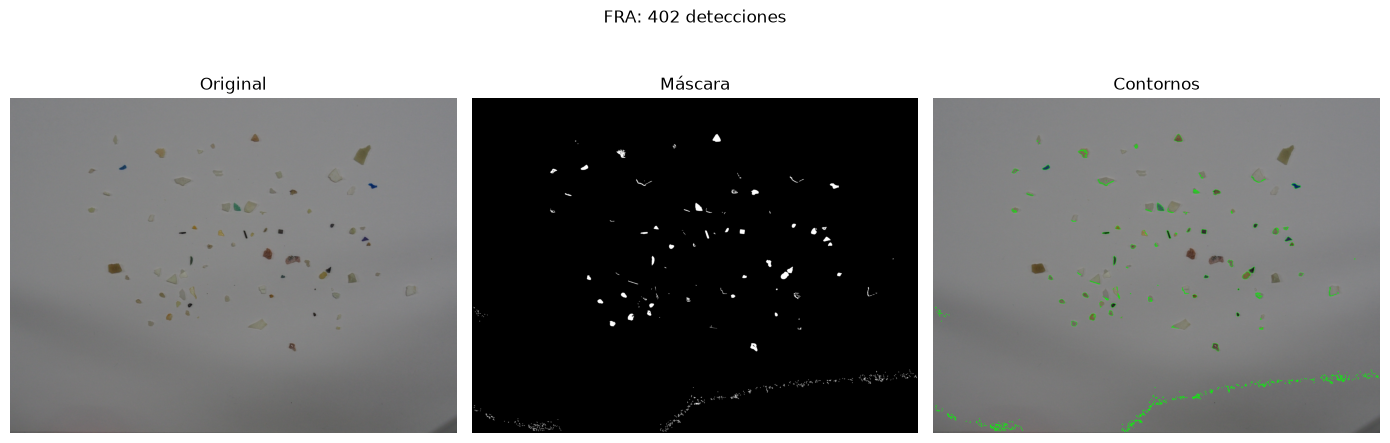

PEL: 61 partículas de entrenamiento


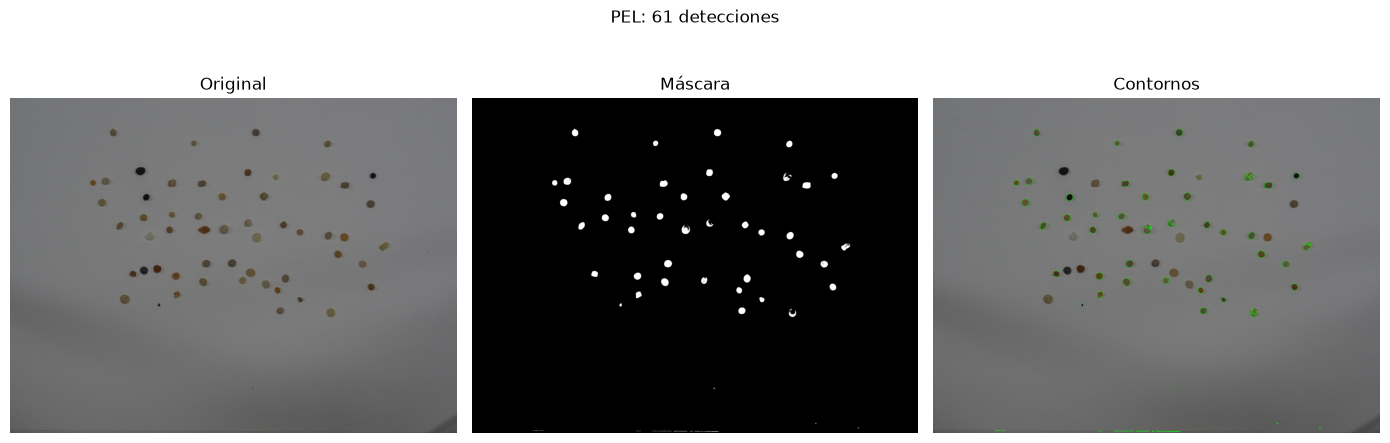

TAR: 49 partículas de entrenamiento


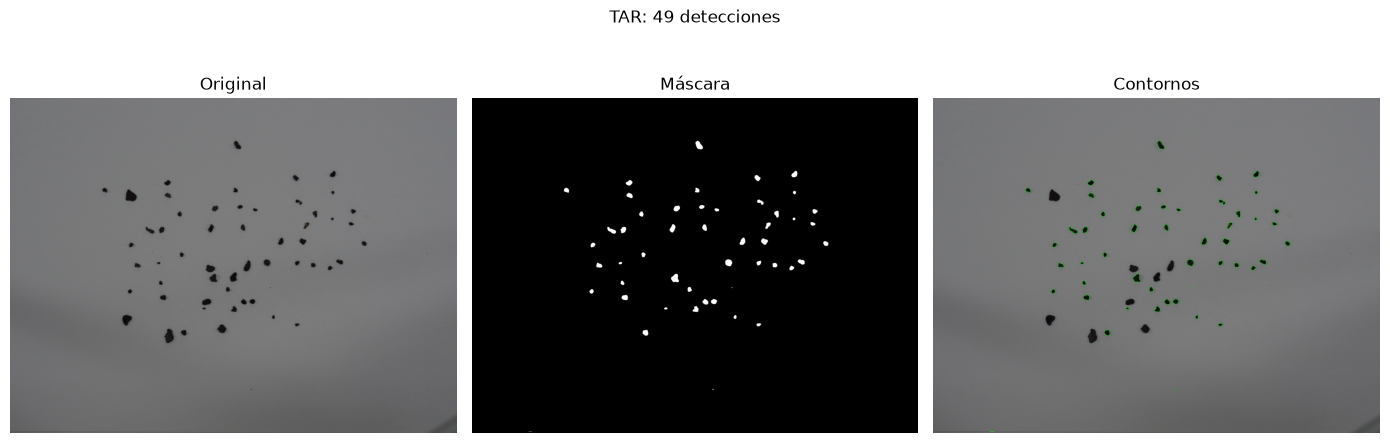

In [14]:
# Parámetros específicos de las imágenes de entrenamiento (NO usar etiquetas de test)
# Ajustamos la segmentación por clase porque las fotos de entrenamiento son distintas.
PARAM_ENTRENO = {'FRA': (20, 30), 'PEL': (30, 60), 'TAR': (30, 60)}
MARGEN = 10

def obtener_contornos(mask, area_min, area_max, margen=MARGEN):
    h, w = mask.shape
    # Detectamos regiones conectadas y medimos su área y posición.
    n, lab, datos, _ = cv2.connectedComponentsWithStats(mask, 8)
    limpia = np.zeros_like(mask)
    for k in range(1,n):
        x,y,an,al,area = datos[k]
        # Quitamos manchas demasiado pequeñas o grandes.
        if area < area_min or area > area_max: continue
        # Descartamos regiones pegadas al borde para evitar recortes incompletos.
        if x <= margen or y <= margen or x+an >= w-margen or y+al >= h-margen: continue
        limpia[lab==k]=255
    cont, _ = cv2.findContours(limpia, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    return limpia,cont

def segmentar_entrenamiento(im, clase):
    gris = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    umbral, area_min = PARAM_ENTRENO[clase]
    # Tomamos la mediana como aproximación del brillo del fondo.
    ref = float(np.median(gris))
    # Las zonas bastante más oscuras que el fondo pasan a blanco.
    mascara = np.uint8(gris < ref - umbral)*255
    return obtener_contornos(mascara, area_min, 5000)

def segmentar_test(im):
    # Fondo local (no se usa el CSV de anotaciones)
    lab = cv2.cvtColor(im, cv2.COLOR_BGR2LAB).astype(np.float32)
    # En el test estimamos el fondo local con un desenfoque fuerte.
    fondo = cv2.GaussianBlur(lab, (0,0),24)
    # Calculamos cuánto se separa cada píxel de ese fondo en LAB.
    delta = np.abs(lab-fondo)
    mascara = np.uint8((delta[:,:,0]>10) | (np.max(delta[:,:,1:],axis=2)>11))*255
    # Rama adicional de objetos muy oscuros sobre el fondo claro.
    # Ayuda a recuperar TAR cuya zona central no quedó completa.
    gris=cv2.cvtColor(im,cv2.COLOR_BGR2GRAY)
    # Sumamos una máscara de zonas muy oscuras para no perder tanto TAR.
    oscuros=np.uint8(gris<135)*255
    mascara=cv2.bitwise_or(mascara,oscuros)
    # El cierre ayuda a rellenar huecos pequeños en las partículas.
    mascara=cv2.morphologyEx(mascara,cv2.MORPH_CLOSE,
                              cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3)))
    # Se filtran los contornos sin watershed: no se dividen partículas artificialmente.
    return obtener_contornos(mascara, 18, 5000, margen=9)

# Mostramos original, máscara y contornos para revisar visualmente la segmentación.
def mostrar(im, mask, cont, titulo):
    copia=im.copy()
    cv2.drawContours(copia,cont,-1,(0,255,0),2)
    fig,ax=plt.subplots(1,3,figsize=(14,5))
    ax[0].imshow(cv2.cvtColor(im,cv2.COLOR_BGR2RGB))
    ax[1].imshow(mask,cmap='gray')
    ax[2].imshow(cv2.cvtColor(copia,cv2.COLOR_BGR2RGB))
    for a,t in zip(ax,['Original','Máscara','Contornos']):
        a.set_title(t);a.axis('off')
    fig.suptitle(f'{titulo}: {len(cont)} detecciones')
    plt.tight_layout();plt.show()

for clase,ruta in ARCHIVOS.items():
    im=cv2.imread(ruta)
    mascara,cs=segmentar_entrenamiento(im,clase)
    print(f'{clase}: {len(cs)} partículas de entrenamiento')
    mostrar(im,mascara,cs,clase)


## 2. Características geométricas y apariencia relativa al fondo

Se utilizan circularidad, solidez, ocupación del rectángulo, razón de ejes, compacidad, contraste normalizado respecto al fondo y color relativo. La normalización relativa evita comparar directamente la iluminación de fotografías tomadas con diferentes condiciones. No se usa el test para ajustar pesos.


In [15]:
def extraer(im, cont):
    # Empezamos por describir la forma del contorno.
    area = cv2.contourArea(cont)
    per = cv2.arcLength(cont, True)
    if area < 1 or per < 1:
        return None
    x,y,w,h = cv2.boundingRect(cont)
    # Circularidad cercana a 1: forma parecida a un círculo.
    circularidad = np.clip(4*np.pi*area/(per*per),0,1)
    # La solidez compara el área con la envolvente convexa.
    solidez = area/max(cv2.contourArea(cv2.convexHull(cont)),1)
    ocupacion = area/(w*h)
    proporcion = min(w,h)/max(w,h)
    eje = proporcion
    # Con suficientes puntos ajustamos una elipse para medir alargamiento.
    if len(cont)>=5:
        (_, _),(e1,e2),_ = cv2.fitEllipse(cont)
        if max(e1,e2)>0: eje=min(e1,e2)/max(e1,e2)
    # Medidas de color y brillo *locales*, sin usar intensidades absolutas de una foto
    h_im,w_im=im.shape[:2]
    borde = max(7, int(max(w,h)*0.5))
    x0=max(0,x-borde); y0=max(0,y-borde)
    x1=min(w_im,x+w+borde); y1=min(h_im,y+h+borde)
    # Recortamos la partícula con un margen de fondo alrededor.
    roi=im[y0:y1,x0:x1]
    mask=np.zeros((y1-y0,x1-x0),np.uint8)
    cv2.drawContours(mask,[cont-np.array([[[x0,y0]]])],-1,255,-1)
    hsv=cv2.cvtColor(roi,cv2.COLOR_BGR2HSV)
    lab=cv2.cvtColor(roi,cv2.COLOR_BGR2LAB)
    entorno=cv2.dilate(mask,np.ones((9,9),np.uint8))
    entorno=cv2.dilate(entorno,np.ones((max(11,borde//2*2+1),)*2,np.uint8))
    # Separamos el entorno cercano de la propia partícula.
    fondo=cv2.bitwise_and(cv2.bitwise_not(mask),entorno)
    # Si hay muy pocos píxeles del entorno, recurrir a todo el recorte exterior
    if cv2.countNonZero(fondo)<20: fondo=cv2.bitwise_not(mask)
    # Comparamos brillo y color del objeto frente a su fondo local.
    Lobj=float(np.median(lab[:,:,0][mask>0]))
    Lfon=float(np.median(lab[:,:,0][fondo>0]))
    diferencia=(Lobj-Lfon)/max(Lfon,1)
    Sobj=float(np.median(hsv[:,:,1][mask>0]))/255
    Sfon=float(np.median(hsv[:,:,1][fondo>0]))/255
    Aobj=float(np.median(lab[:,:,1][mask>0]))
    Bobj=float(np.median(lab[:,:,2][mask>0]))
    Afon=float(np.median(lab[:,:,1][fondo>0]))
    Bfon=float(np.median(lab[:,:,2][fondo>0]))
    # Fracción de píxeles internos significativamente más oscuros que su fondo
    # Guardamos también qué parte del objeto es muy oscura: puede ayudar con TAR.
    oscuro=float(np.mean(lab[:,:,0][mask>0] < Lfon*0.65))
    # No se incluye tamaño: fotografías con escalas muy diferentes
    # Cada contorno queda convertido en 10 números que usará el clasificador.
    return [circularidad,solidez,ocupacion,proporcion,eje,diferencia,
            Sobj-Sfon,(Aobj-Afon)/64,(Bobj-Bfon)/64,oscuro]


## 3. Selección del clasificador mediante validación en entrenamiento

Probamos tres técnicas tradicionales: k-NN, SVM y Random Forest. Elegimos la que consigue mayor **F1 macro** en validación cruzada estratificada con las muestras de entrenamiento (evita escoger un método por favorecer únicamente a FRA). La selección no utiliza el CSV del test.

La validación tiene una limitación: todas las partículas de cada clase proceden de una misma fotografía; por eso la puntuación de validación puede resultar optimista respecto a fotografías nuevas.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import f1_score

# X tendrá las características y Y la clase real de cada imagen de entrenamiento.
X, Y = [], []
for clase, ruta in ARCHIVOS.items():
    imagen = cv2.imread(ruta)
    _, contornos_entreno = segmentar_entrenamiento(imagen, clase)
    for c in contornos_entreno:
        # Una fila por partícula: guardamos su vector y su etiqueta.
        v = extraer(imagen, c)
        if v is not None and np.all(np.isfinite(v)):
            X.append(v)
            Y.append(clase)
X = np.asarray(X, dtype=float)
Y = np.asarray(Y)
print('Partículas de entrenamiento:', {s:int(sum(Y==s)) for s in CLASES})

# Probamos varios clasificadores clásicos, sin redes neuronales.
modelos = {
    'k-NN': make_pipeline(SimpleImputer(), StandardScaler(), KNeighborsClassifier(n_neighbors=5, weights='distance')),
    'SVM-RBF': make_pipeline(SimpleImputer(), StandardScaler(), SVC(C=2, gamma='scale', class_weight='balanced')),
    'Random Forest': make_pipeline(SimpleImputer(), RandomForestClassifier(n_estimators=240, max_features='sqrt', min_samples_leaf=2, class_weight='balanced', random_state=33)),
    'Extra Trees': make_pipeline(SimpleImputer(), ExtraTreesClassifier(n_estimators=240, min_samples_leaf=2, class_weight='balanced', random_state=33)),
}
# Validación en 5 partes manteniendo una proporción similar de clases.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=33)
resultados_cv = {}
for nombre, modelo in modelos.items():
    # Comparamos por F1 macro para no favorecer tanto a la clase mayoritaria.
    scores = cross_val_score(modelo, X, Y, scoring='f1_macro', cv=cv)
    resultados_cv[nombre] = float(scores.mean())
    print(f'{nombre:14s} F1 macro validación: {scores.mean():.3f} ± {scores.std():.3f}')

# Elegimos el modelo con mejor media de validación.
mejor_nombre = max(resultados_cv, key=resultados_cv.get)
clasificador = modelos[mejor_nombre]
# Lo entrenamos con todo el entrenamiento, sin utilizar el CSV de test.
clasificador.fit(X, Y)
print('Modelo elegido (solo entrenamiento):', mejor_nombre)

# Adaptamos el vector a una fila para que predict nos dé una etiqueta.
def predecir_clase(vector):
    return str(clasificador.predict(np.asarray(vector).reshape(1, -1))[0])

Partículas de entrenamiento: {'FRA': 402, 'PEL': 61, 'TAR': 49}
k-NN           F1 macro validación: 0.858 ± 0.051
SVM-RBF        F1 macro validación: 0.901 ± 0.030
Random Forest  F1 macro validación: 0.858 ± 0.049
Extra Trees    F1 macro validación: 0.871 ± 0.040
Modelo elegido (solo entrenamiento): SVM-RBF


## 4. Aplicación al test

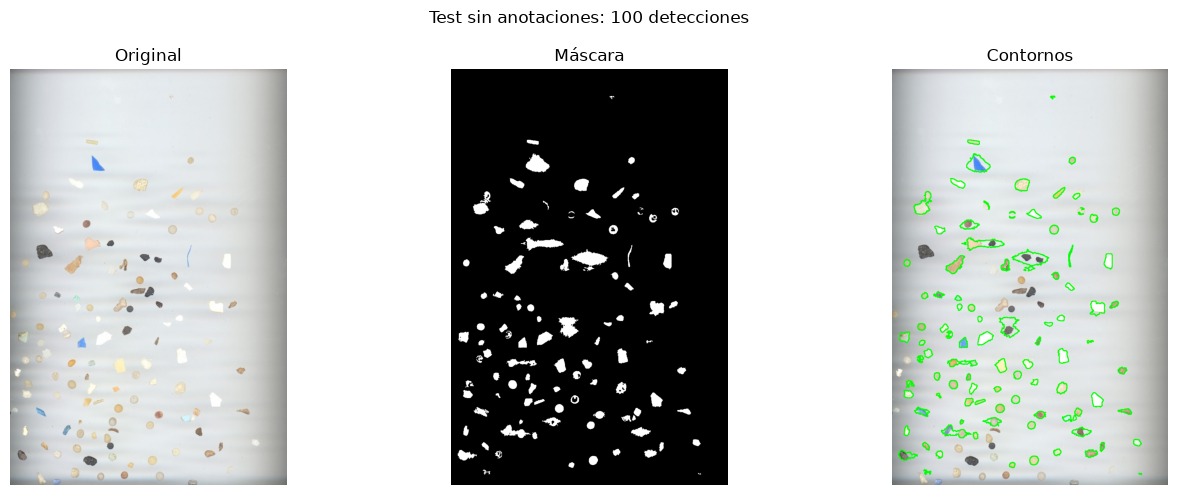

Predicciones: 100 {'FRA': 95, 'PEL': 5, 'TAR': 0}


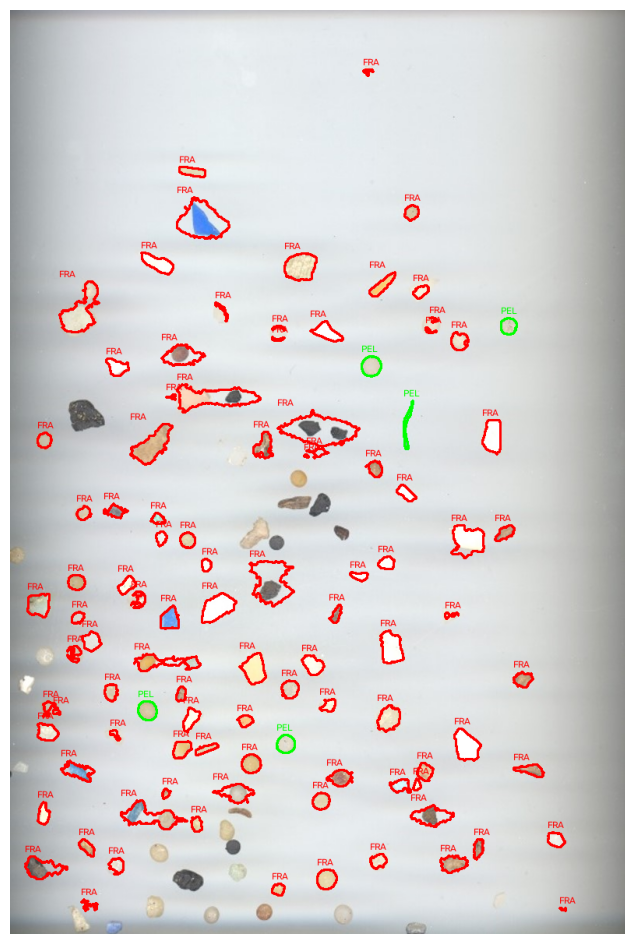

In [17]:
im=cv2.imread('MPs_test.jpg')
# Primero segmentamos el test, sin mirar todavía sus anotaciones.
mask,contornos=segmentar_test(im)
mostrar(im,mask,contornos,'Test sin anotaciones')
predicciones=[]
vista=im.copy()
colores={'FRA':(0,0,255),'PEL':(0,255,0),'TAR':(255,0,0)}
for ct in contornos:
    # A cada región le calculamos las mismas características del entrenamiento.
    v=extraer(im,ct)
    if v is None:continue
    # El modelo decide si es FRA, PEL o TAR.
    clase=predecir_clase(v)
    x,y,w,h=cv2.boundingRect(ct)
    # Guardamos la clase predicha y su rectángulo para evaluarlo después.
    predicciones.append({'label':clase,'bbox':(x,y,x+w,y+h)})
    cv2.drawContours(vista,[ct],-1,colores[clase],2)
    cv2.putText(vista,clase,(x,max(15,y-5)),cv2.FONT_HERSHEY_SIMPLEX,.42,colores[clase],1)
print('Predicciones:',len(predicciones),{s:sum(p['label']==s for p in predicciones) for s in CLASES})
plt.figure(figsize=(10,12));plt.imshow(cv2.cvtColor(vista,cv2.COLOR_BGR2RGB));plt.axis('off');plt.show()


## 5. Evaluación con anotaciones del test

Este es el **único apartado** que lee `MPs_test_bbs.csv`. Las métricas de clasificación se calculan sobre partículas emparejadas individualmente por IoU; por eso se muestra también cuántas anotaciones quedaron sin detectar y cuántas detecciones no pudieron emparejarse.


Anotaciones: 120 Predicciones: 100
Emparejadas: 88 No detectadas: 32
Detecciones sin anotación: 12
Cobertura: 0.733


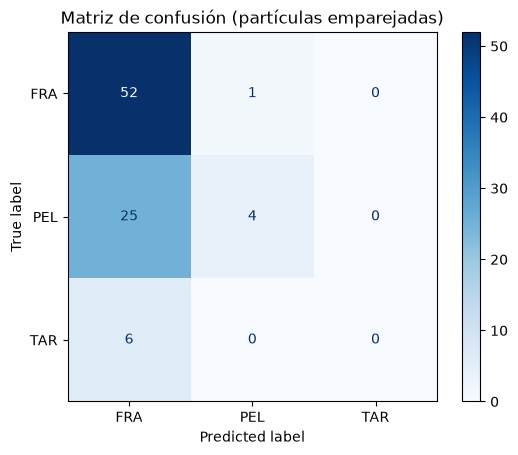

              precision    recall  f1-score   support

         FRA      0.627     0.981     0.765        53
         PEL      0.800     0.138     0.235        29
         TAR      0.000     0.000     0.000         6

    accuracy                          0.636        88
   macro avg      0.476     0.373     0.333        88
weighted avg      0.641     0.636     0.538        88

Accuracy: 0.6363636363636364


In [18]:
# IoU mide cuánto coinciden el rectángulo detectado y el anotado.
def iou(a,b):
    x1=max(a[0],b[0]);y1=max(a[1],b[1]);x2=min(a[2],b[2]);y2=min(a[3],b[3])
    inter=max(0,x2-x1)*max(0,y2-y1)
    aa=max(0,a[2]-a[0])*max(0,a[3]-a[1])
    bb=max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return inter/max(aa+bb-inter,1e-6)

# Solo ahora leemos el CSV, para evaluar y no para entrenar.
anotaciones=[]
with open('MPs_test_bbs.csv',newline='',encoding='utf-8-sig') as f:
    for fila in csv.DictReader(f):
        clase=fila['label'].strip().upper()
        if clase in CLASES:
            caja=tuple(int(float(fila[z])) for z in ['x_min','y_min','x_max','y_max'])
            anotaciones.append({'label':clase,'bbox':caja})

# Exigimos un mínimo de solapamiento para dar por emparejadas dos partículas.
UMBRAL_IOU=0.2
posibles=[]
# Buscamos parejas posibles entre anotaciones y predicciones.
for i,a in enumerate(anotaciones):
    for j,p in enumerate(predicciones):
        solape=iou(a['bbox'],p['bbox'])
        if solape>=UMBRAL_IOU:posibles.append((solape,i,j))
# Emparejamos empezando por los mejores solapamientos, sin repetir cajas.
usadas_a=set();usadas_p=set();parejas=[]
for score,i,j in sorted(posibles,reverse=True):
    if i not in usadas_a and j not in usadas_p:
        usadas_a.add(i);usadas_p.add(j);parejas.append((i,j))
# Comparamos etiquetas solo para las partículas que conseguimos emparejar.
real=[anotaciones[i]['label'] for i,j in parejas]
pred=[predicciones[j]['label'] for i,j in parejas]
print('Anotaciones:',len(anotaciones),'Predicciones:',len(predicciones))
print('Emparejadas:',len(parejas),'No detectadas:',len(anotaciones)-len(parejas))
print('Detecciones sin anotación:',len(predicciones)-len(parejas))
# Cobertura = porcentaje de anotaciones que han tenido detección.
print('Cobertura:',round(len(parejas)/len(anotaciones),3) if anotaciones else 0)
if real:
    # La matriz muestra en qué categorías se confunde el modelo.
    matriz=confusion_matrix(real,pred,labels=CLASES)
    ConfusionMatrixDisplay(matriz,display_labels=CLASES).plot(cmap='Blues',values_format='d')
    plt.title('Matriz de confusión (partículas emparejadas)');plt.show()
    # Precision, recall y F1 por clase: más útiles que mirar solo accuracy.
    print(classification_report(real,pred,labels=CLASES,zero_division=0,digits=3))
    print('Accuracy:',accuracy_score(real,pred))
else:
    print('No se pudo emparejar ninguna partícula. Revisar las máscaras.')